In [2]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns



In [3]:
df = pd.read_csv('../data/train.csv')

In [4]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
# Dataset information
df.info()

# Dataset shape
print("Dataset Shape:", df.shape)

# Statistical summary
display(df.describe())

# Missing values
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB
Dataset Shape: (891, 12)


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [6]:
# Survival count
print(df['Survived'].value_counts())

# Survival percentage
print(df['Survived'].value_counts(normalize=True) * 100)

Survived
0    549
1    342
Name: count, dtype: int64
Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64


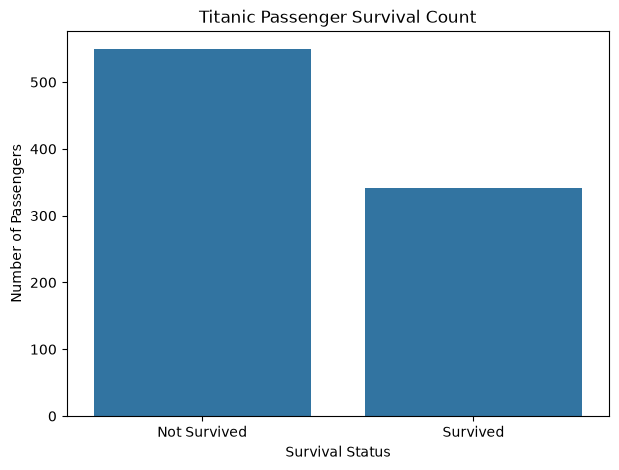

In [7]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Survived')

plt.title('Titanic Passenger Survival Count')
plt.xlabel('Survival Status')
plt.ylabel('Number of Passengers')

plt.xticks([0, 1], ['Not Survived', 'Survived'])

plt.show()

In [8]:
# Gender-wise survival count
gender_survival = pd.crosstab(
    df['Sex'],
    df['Survived']
)

print(gender_survival)

Survived    0    1
Sex               
female     81  233
male      468  109


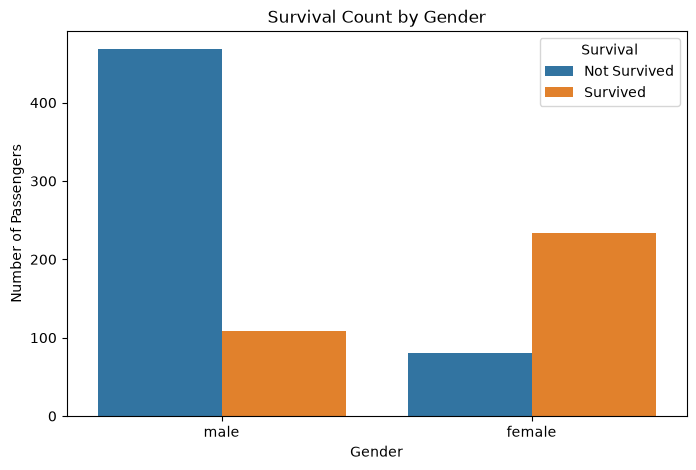

In [9]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Sex', hue='Survived')

plt.title('Survival Count by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Passengers')

plt.legend(title='Survival', labels=['Not Survived', 'Survived'])

plt.show()

In [10]:
gender_survival_percentage = pd.crosstab(
    df['Sex'],
    df['Survived'],
    normalize='index'
) * 100

print(gender_survival_percentage.round(2))

Survived      0      1
Sex                   
female    25.80  74.20
male      81.11  18.89


In [11]:
# Survival count by passenger class
pclass_survival = pd.crosstab(
    df['Pclass'],
    df['Survived']
)

print(pclass_survival)

Survived    0    1
Pclass            
1          80  136
2          97   87
3         372  119


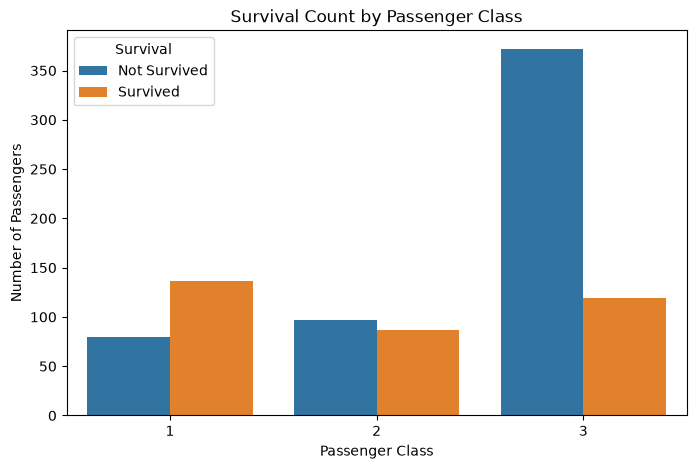

In [12]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Pclass', hue='Survived')

plt.title('Survival Count by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Number of Passengers')

plt.legend(title='Survival', labels=['Not Survived', 'Survived'])

plt.show()

In [13]:
pclass_percentage = pd.crosstab(
    df['Pclass'],
    df['Survived'],
    normalize='index'
) * 100

print(pclass_percentage.round(2))

Survived      0      1
Pclass                
1         37.04  62.96
2         52.72  47.28
3         75.76  24.24


In [14]:
pclass_percentage = pd.crosstab(
    df['Pclass'],
    df['Survived'],
    normalize='index'
) * 100

print(pclass_percentage.round(2))

Survived      0      1
Pclass                
1         37.04  62.96
2         52.72  47.28
3         75.76  24.24


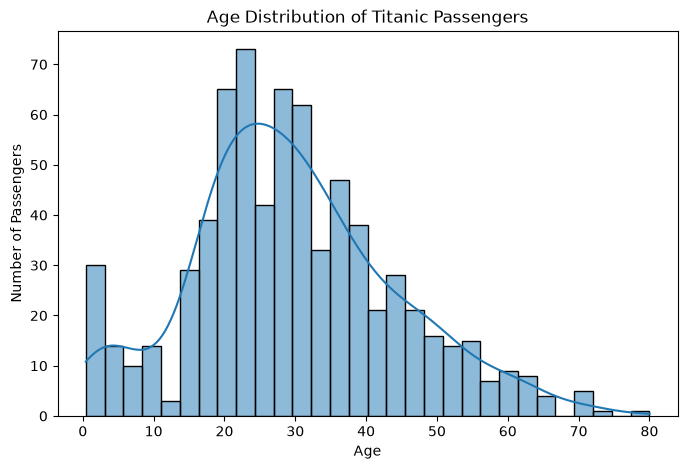

In [15]:
# Age distribution
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='Age', bins=30, kde=True)

plt.title('Age Distribution of Titanic Passengers')
plt.xlabel('Age')
plt.ylabel('Number of Passengers')

plt.show()

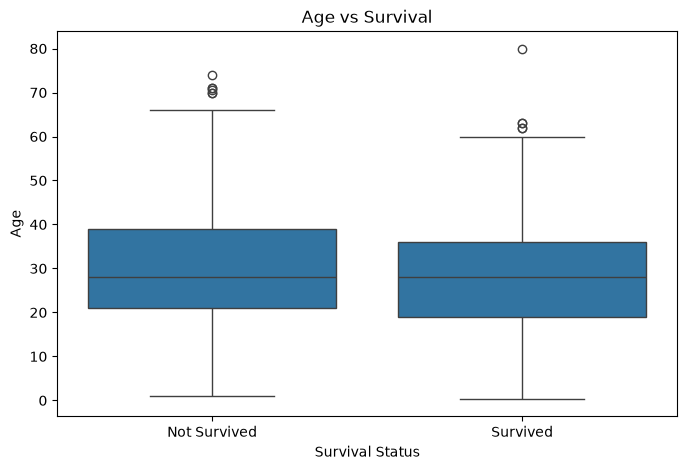

In [16]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='Survived', y='Age')

plt.title('Age vs Survival')
plt.xlabel('Survival Status')
plt.ylabel('Age')

plt.xticks([0, 1], ['Not Survived', 'Survived'])

plt.show()

In [17]:
# Create age groups
df['AgeGroup'] = pd.cut(
    df['Age'],
    bins=[0, 12, 18, 35, 60, 100],
    labels=['Child', 'Teenager', 'Young Adult', 'Adult', 'Senior']
)

# Survival by age group
age_survival = pd.crosstab(
    df['AgeGroup'],
    df['Survived'],
    normalize='index'
) * 100

print(age_survival.round(2))

Survived         0      1
AgeGroup                 
Child        42.03  57.97
Teenager     57.14  42.86
Young Adult  61.73  38.27
Adult        60.00  40.00
Senior       77.27  22.73


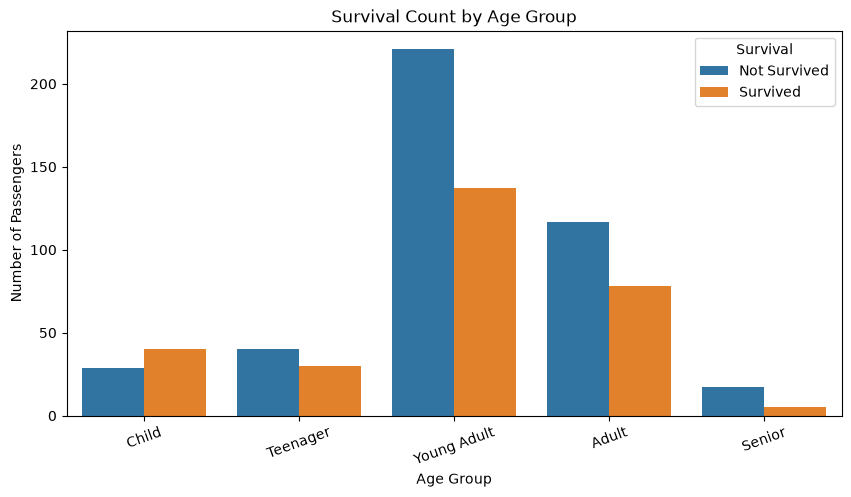

In [18]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='AgeGroup',
    hue='Survived'
)

plt.title('Survival Count by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Number of Passengers')

plt.xticks(rotation=20)
plt.legend(title='Survival', labels=['Not Survived', 'Survived'])

plt.show()

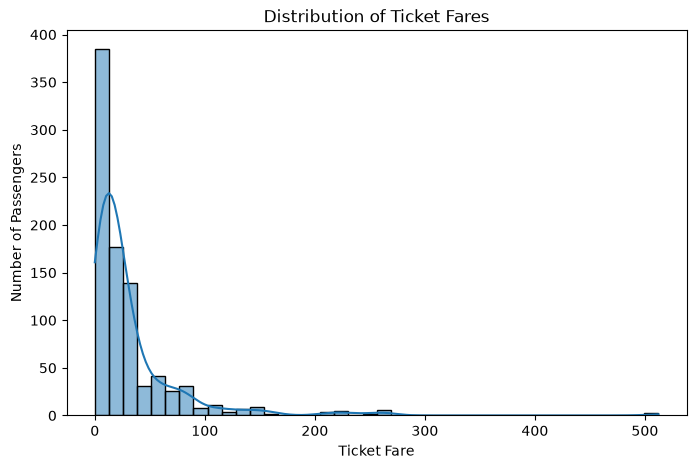

In [19]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='Fare', bins=40, kde=True)

plt.title('Distribution of Ticket Fares')
plt.xlabel('Ticket Fare')
plt.ylabel('Number of Passengers')

plt.show()

In [20]:
fare_survival = pd.crosstab(
    pd.qcut(df['Fare'], 4),
    df['Survived'],
    normalize='index'
) * 100

print(fare_survival.round(2))

Survived             0      1
Fare                         
(-0.001, 7.91]   80.27  19.73
(7.91, 14.454]   69.64  30.36
(14.454, 31.0]   54.50  45.50
(31.0, 512.329]  41.89  58.11


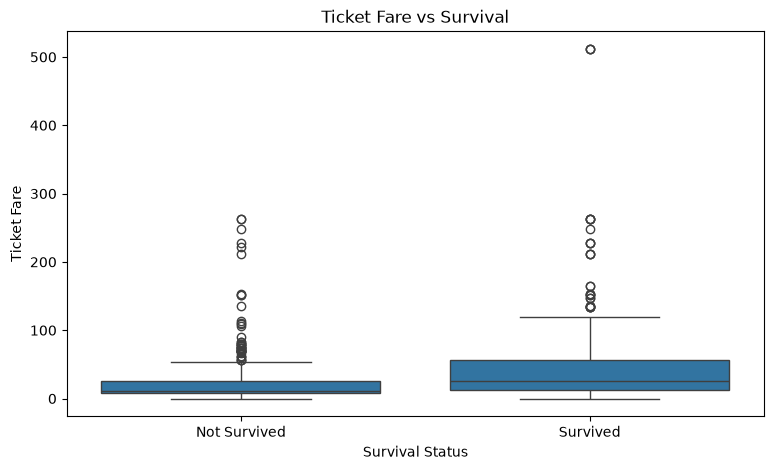

In [21]:
plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x='Survived', y='Fare')

plt.title('Ticket Fare vs Survival')
plt.xlabel('Survival Status')
plt.ylabel('Ticket Fare')
plt.xticks([0, 1], ['Not Survived', 'Survived'])

plt.show()

In [22]:
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1

df[['SibSp', 'Parch', 'FamilySize']].head()

,SibSp,Parch,FamilySize
0,1,0,2
1,1,0,2
2,0,0,1
3,1,0,2
4,0,0,1


In [23]:
family_survival = pd.crosstab(
    df['FamilySize'],
    df['Survived'],
    normalize='index'
) * 100

print(family_survival.round(2))

Survived         0      1
FamilySize               
1            69.65  30.35
2            44.72  55.28
3            42.16  57.84
4            27.59  72.41
5            80.00  20.00
6            86.36  13.64
7            66.67  33.33
8           100.00   0.00
11          100.00   0.00


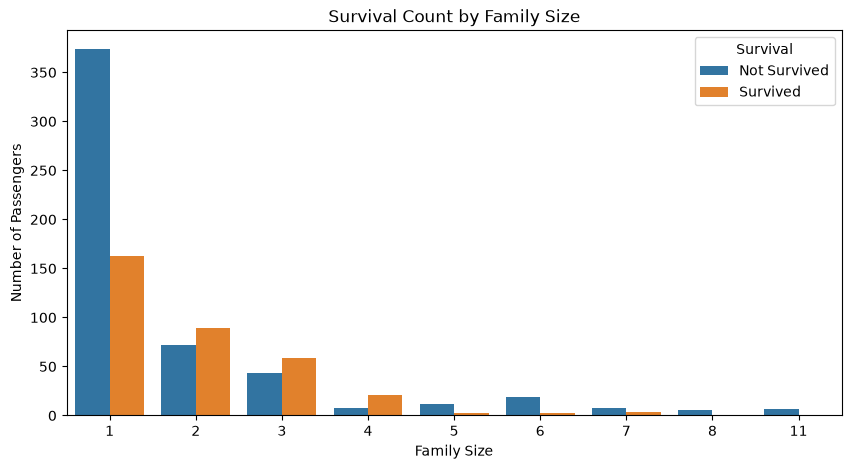

In [24]:
plt.figure(figsize=(10, 5))

sns.countplot(data=df, x='FamilySize', hue='Survived')

plt.title('Survival Count by Family Size')
plt.xlabel('Family Size')
plt.ylabel('Number of Passengers')
plt.legend(title='Survival', labels=['Not Survived', 'Survived'])

plt.show()

In [25]:
df['TravelAlone'] = np.where(
    df['FamilySize'] == 1,
    'Alone',
    'With Family'
)

df[['FamilySize', 'TravelAlone']].head(10)

,FamilySize,TravelAlone
0,2,With Family
1,2,With Family
2,1,Alone
3,2,With Family
4,1,Alone
5,1,Alone
6,1,Alone
7,5,With Family
8,3,With Family
9,2,With Family


In [26]:
alone_survival = pd.crosstab(
    df['TravelAlone'],
    df['Survived'],
    normalize='index'
) * 100

print(alone_survival.round(2))

Survived         0      1
TravelAlone              
Alone        69.65  30.35
With Family  49.44  50.56


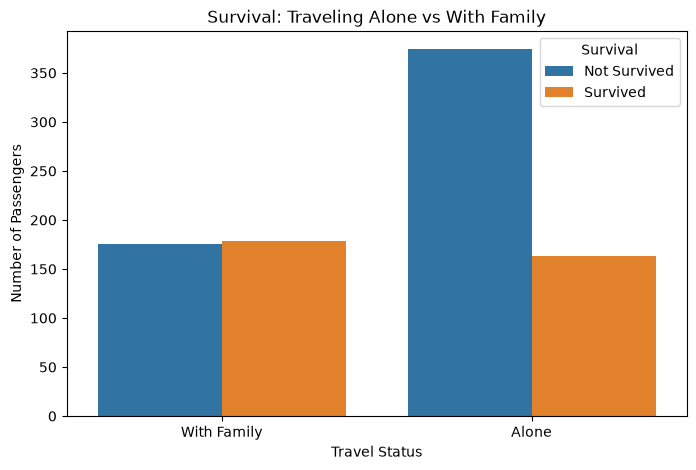

In [27]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='TravelAlone', hue='Survived')

plt.title('Survival: Traveling Alone vs With Family')
plt.xlabel('Travel Status')
plt.ylabel('Number of Passengers')
plt.legend(title='Survival', labels=['Not Survived', 'Survived'])

plt.show()

In [28]:
print(df['Embarked'].value_counts())

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64


In [29]:
embarked_survival = pd.crosstab(
    df['Embarked'],
    df['Survived'],
    normalize='index'
) * 100

print(embarked_survival.round(2))

Survived      0      1
Embarked              
C         44.64  55.36
Q         61.04  38.96
S         66.30  33.70


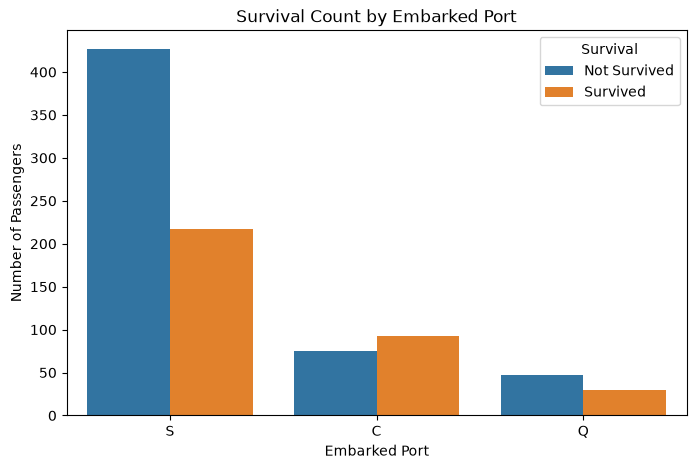

In [30]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Embarked', hue='Survived')

plt.title('Survival Count by Embarked Port')
plt.xlabel('Embarked Port')
plt.ylabel('Number of Passengers')
plt.legend(title='Survival', labels=['Not Survived', 'Survived'])

plt.show()

In [31]:
missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])

Age         177
Cabin       687
Embarked      2
AgeGroup    177
dtype: int64


In [32]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage[missing_percentage > 0].round(2))

Age         19.87
Cabin       77.10
Embarked     0.22
AgeGroup    19.87
dtype: float64


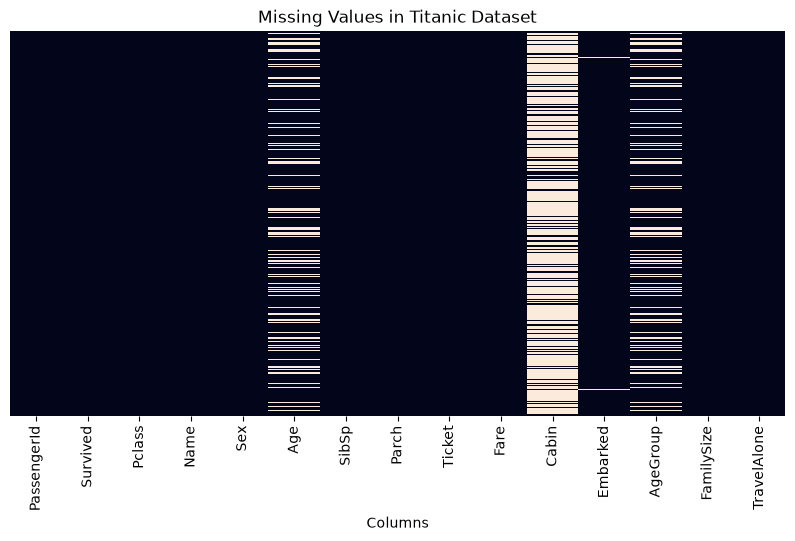

In [33]:
plt.figure(figsize=(10, 5))

sns.heatmap(df.isnull(), cbar=False, yticklabels=False)

plt.title('Missing Values in Titanic Dataset')
plt.xlabel('Columns')
plt.show()

In [34]:
median_age = df['Age'].median()

df['Age'] = df['Age'].fillna(median_age)

print("Median Age:", median_age)
print("Missing Age Values:", df['Age'].isnull().sum())

Median Age: 28.0
Missing Age Values: 0


In [35]:
embarked_mode = df['Embarked'].mode()[0]

df['Embarked'] = df['Embarked'].fillna(embarked_mode)

print("Most Common Port:", embarked_mode)
print("Missing Embarked Values:", df['Embarked'].isnull().sum())


Most Common Port: S
Missing Embarked Values: 0


In [36]:
df['HasCabin'] = df['Cabin'].notnull().astype(int)

print(df['HasCabin'].value_counts())

HasCabin
0    687
1    204
Name: count, dtype: int64


In [37]:
df.drop(columns=['Cabin'], inplace=True)

print(df.columns)

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Embarked', 'AgeGroup', 'FamilySize',
       'TravelAlone', 'HasCabin'],
      dtype='str')


C:\Users\RAM\AppData\Local\Temp\ipykernel_10664\1445805345.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=['Cabin'], inplace=True)


In [38]:
df = df.drop(columns=['Cabin'], errors='ignore')

print(df.columns)

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Embarked', 'AgeGroup', 'FamilySize',
       'TravelAlone', 'HasCabin'],
      dtype='str')


In [39]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values in Each Column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Embarked         0
AgeGroup       177
FamilySize       0
TravelAlone      0
HasCabin         0
dtype: int64

Total Missing Values:
177


In [40]:
df['AgeGroup'] = pd.cut(
    df['Age'],
    bins=[0, 12, 18, 35, 60, 100],
    labels=['Child', 'Teenager', 'Young Adult', 'Adult', 'Senior']
)

print("Missing AgeGroup Values:", df['AgeGroup'].isnull().sum())

Missing AgeGroup Values: 0


In [41]:
print("Total Missing Values:", df.isnull().sum().sum())

Total Missing Values: 0


In [42]:
print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 0


In [43]:
print("Dataset Shape:", df.shape)

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Dataset Shape: (891, 15)
Total Rows: 891
Total Columns: 15


In [44]:
df.info()

display(df.describe(include='all'))

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   PassengerId  891 non-null    int64   
 1   Survived     891 non-null    int64   
 2   Pclass       891 non-null    int64   
 3   Name         891 non-null    str     
 4   Sex          891 non-null    str     
 5   Age          891 non-null    float64 
 6   SibSp        891 non-null    int64   
 7   Parch        891 non-null    int64   
 8   Ticket       891 non-null    str     
 9   Fare         891 non-null    float64 
 10  Embarked     891 non-null    str     
 11  AgeGroup     891 non-null    category
 12  FamilySize   891 non-null    int64   
 13  TravelAlone  891 non-null    str     
 14  HasCabin     891 non-null    int64   
dtypes: category(1), float64(2), int64(7), str(5)
memory usage: 98.7 KB


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,AgeGroup,FamilySize,TravelAlone,HasCabin
count,891.000000,891.000000,891.000000,891,891,891.000000,891.000000,891.000000,891,891.000000,891,891,891.000000,891,891.000000
unique,NaN,NaN,NaN,891,2,NaN,NaN,NaN,681,NaN,3,5,NaN,2,NaN
top,NaN,NaN,NaN,"Braund, Mr. Owen Harris",male,NaN,NaN,NaN,347082,NaN,S,Young Adult,NaN,Alone,NaN
freq,NaN,NaN,NaN,1,577,NaN,NaN,NaN,7,NaN,646,535,NaN,537,NaN
mean,446.000000,0.383838,2.308642,NaN,NaN,29.361582,0.523008,0.381594,NaN,32.204208,NaN,NaN,1.904602,NaN,0.228956
std,257.353842,0.486592,0.836071,NaN,NaN,13.019697,1.102743,0.806057,NaN,49.693429,NaN,NaN,1.613459,NaN,0.420397
min,1.000000,0.000000,1.000000,NaN,NaN,0.420000,0.000000,0.000000,NaN,0.000000,NaN,NaN,1.000000,NaN,0.000000
25%,223.500000,0.000000,2.000000,NaN,NaN,22.000000,0.000000,0.000000,NaN,7.910400,NaN,NaN,1.000000,NaN,0.000000
50%,446.000000,0.000000,3.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN,1.000000,NaN,0.000000
75%,668.500000,1.000000,3.000000,NaN,NaN,35.000000,1.000000,0.000000,NaN,31.000000,NaN,NaN,2.000000,NaN,0.000000


In [45]:
print("TITANIC DATASET - KEY FINDINGS")
print("-" * 40)

print("Total Passengers:", len(df))

print("Survival Rate:",
      round(df['Survived'].mean() * 100, 2), "%")

print("Female Survival Rate:",
      round(df.loc[df['Sex'] == 'female', 'Survived'].mean() * 100, 2), "%")

print("Male Survival Rate:",
      round(df.loc[df['Sex'] == 'male', 'Survived'].mean() * 100, 2), "%")

print("Average Passenger Age:",
      round(df['Age'].mean(), 2))

print("Average Ticket Fare:",
      round(df['Fare'].mean(), 2))

print("Passengers Traveling Alone:",
      (df['TravelAlone'] == 'Alone').sum())

print("Passengers With Cabin Record:",
      df['HasCabin'].sum())

TITANIC DATASET - KEY FINDINGS
----------------------------------------
Total Passengers: 891
Survival Rate: 38.38 %
Female Survival Rate: 74.2 %
Male Survival Rate: 18.89 %
Average Passenger Age: 29.36
Average Ticket Fare: 32.2
Passengers Traveling Alone: 537
Passengers With Cabin Record: 204


# Titanic Dataset — Exploratory Data Analysis

## Conclusion

The Titanic dataset contains 891 passenger records.

Key findings:

- Overall survival rate was approximately 38.38%.
- Female passengers had a higher survival rate than male passengers.
- Passenger class showed an association with survival.
- Age and ticket fare distributions varied across survival groups.
- Family size and traveling alone were also explored.
- Missing values were handled during data cleaning.
- A new feature, `HasCabin`, was created from cabin information.

## Final Note

This exploratory data analysis helped identify important patterns and prepare the dataset for machine learning.

**Next Step:** Feature Engineering and Machine Learning Model Development.